# Evaluation (M11)

This notebook reads the saved tables of `reports/results/`, written by `logtriage evaluate`. It calls package functions only: it fits nothing, scores nothing, makes no LLM call and opens no ground truth. To regenerate the tables, run `uv run logtriage evaluate` from the repository root.

The santos reading against `reports/targets.md` comes first (§10.7). Manual faithfulness is NOT MEASURED (D67) and human evaluation is NOT PERFORMED (D68).

In [1]:
from pathlib import Path

from IPython.display import Markdown, display

from logtriage.eval import results_text, viz

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
saved = results_text.Saved(ROOT / "reports" / "results")

## 1. Santos against the frozen targets

In [2]:
display(Markdown(results_text.targets_section(saved)))

## 1. Santos against the frozen targets

This is the primary reading (§10.7). `reports/targets.md` names santos only, so the pooled column is additional and is not a target reading.

| Target | Value | Santos | Pooled test testbeds |
|---|---|---|---|
| Phase recall | ≥ 80% of phases with traces | 5 of 9 (55.6%), **missed** | 13 of 27 (48.1%) |
| Incidents per day | ≤ 25 | 1.11, **met** | not pooled: santos 1.11, wardbeck 4.21, harrison 5.87 |
| Fewer incidents than raw IDS alerts | ≥ 90% | 99.996%, **met** | not pooled: santos 99.996%, wardbeck 99.977%, harrison 99.998% |
| ATT&CK top-3, strict | ≥ 70% of malicious incidents | 2 of 2 (100.0%), **met, on 2 incidents** | 4 of 6 (66.7%), below 70% |
| Manual faithfulness | ≥ 90% with the Verifier, and higher than without | **NOT MEASURED** (D67) | **NOT MEASURED** (D67) |

Manual faithfulness has no human annotators and is not reported as met or missed. The AI-annotated number in section 6 is a different measure and does not stand in for it. Human evaluation is **NOT PERFORMED** (D68).

**Freeze reference.** The targets are the content of `reports/targets.md` at commit `3684424`, tag `targets-frozen`, not `m3-done`. Commit `0ae17bf` changed only line 3, the placeholder for the hash; no target number or definition changed.

**Santos runs (D40).** Santos was scored three times by the frozen supervised models. The committed CSVs are run 1. The error file and the reading of the results were chosen after seeing santos numbers; no model, feature, threshold, config or definition was. The `dns` thresholds are uninformative.

**How the santos reports came to exist (D47).** They come from an accidental run: a stub test in `tests/test_smoke.py` called `investigate` after it stopped being a stub, so `pytest` ran a real investigation at 08:59–09:01 UTC on 2026-11-06, with the frozen prompts and code, 4 s before the freeze commit. The reports were kept and santos was not run again, because a second run would be the real breach. No prompt, retrieval, config or code changed because of its output.


## 2. Per testbed and pooled

In [3]:
display(Markdown(results_text.phase_section(saved)))

### Phase recall

| Testbed | Primary | All parsed | Without `dnsteal_exfil` | Missed |
|---|---|---|---|---|
| santos | 5/9 (55.6%) | 5/9 (55.6%) | 5/8 (62.5%) | cracking dnsteal_exfil network_scans service_stop |
| wardbeck | 5/9 (55.6%) | 5/9 (55.6%) | 5/8 (62.5%) | cracking dnsteal_exfil network_scans service_stop |
| harrison | 3/9 (33.3%) | 3/9 (33.3%) | 3/8 (37.5%) | cracking dnsteal_exfil network_scans service_scans service_stop webshell |
| pooled | 13/27 (48.1%) | 13/27 (48.1%) | 13/24 (54.2%) |  |
| russellmitchell | 6/10 (60.0%) | 6/10 (60.0%) | 6/9 (66.7%) | dnsteal dnsteal_exfil network_scans service_stop |

No phase is credited through `dns` on any testbed.

Unclipped DNS secondary, quoted from M5 and not recomputed. It exists for russellmitchell and santos only, not for `wardbeck` and `harrison` (D61), because it needs a second scoring pass and each new testbed runs once:

| Testbed | Phases | Note |
|---|---|---|
| russellmitchell | 6/10 | 7.47 incidents/day, 17 dns windows, 0 true |
| santos | 7/9 | 1.11 incidents/day, 1,012 dns windows, 5 true |


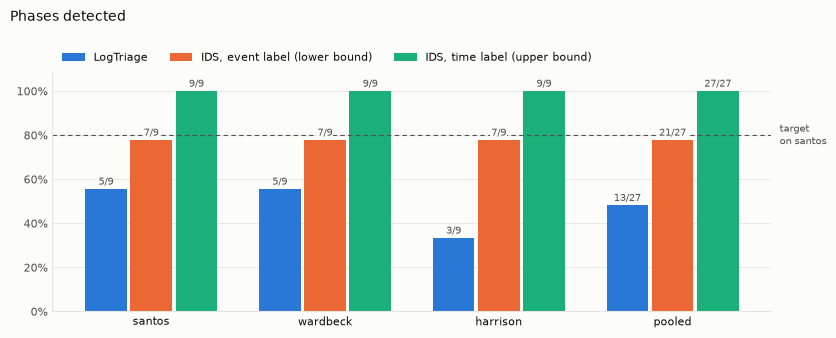

In [4]:
comparison = results_text.recall_comparison(saved)
figure = viz.plot_phase_recall_comparison(
    comparison, ROOT / "reports" / "figures" / "eval_phase_recall.png"
)

In [5]:
display(Markdown(results_text.alerts_section(saved)))

### Incidents and alert reduction

Not pooled (§10.7).

| Testbed | Days | Incidents | Per day | Anomalous windows/day | Raw alerts/day | Grouped alerts/day | vs raw | vs grouped | vs windows | Budget used |
|---|---|---|---|---|---|---|---|---|---|---|
| santos | 2.697 | 3 | 1.11 | 1.85 | 30,774 | 86.4 | 99.996% | 98.7% | 40.0% | 4.4% |
| wardbeck | 3.325 | 14 | 4.21 | 5.71 | 18,340 | 132.6 | 99.977% | 96.8% | 26.3% | 16.8% |
| harrison | 1.705 | 10 | 5.87 | 43.99 | 280,562 | 95.0 | 99.998% | 93.8% | 86.7% | 23.5% |
| russellmitchell | 1.874 | 7 | 3.73 | 12.80 | 15,704 | 89.6 | 99.976% | 95.8% | 70.8% | 14.9% |

**The incident budget is mostly unused.** `q` 0.999 is the only grid value inside the budget on dev, and the grid has nothing between 0.995 and 0.999. So phase recall misses its target with most of the budget unused; whether a finer `q` would recover phases was not tested. The grid was not changed after santos was scored.


In [6]:
display(Markdown(results_text.verdict_section(saved)))

### Verdicts

Predicted by true class, label-ambiguous incidents left out. F1 counts `uncertain` as non-benign (§10.2). Pooled sums the three test testbeds (D62).

| Testbed | mal./true mal. | mal./true ben. | unc./true mal. | unc./true ben. | ben./true mal. | ben./true ben. | F1 | F1 with ambiguous | ML-only F1 |
|---|---|---|---|---|---|---|---|---|---|
| santos | 2 | 0 | 0 | 1 | 0 | 0 | 0.800 | 0.800 | 0.800 |
| wardbeck | 2 | 0 | 0 | 12 | 0 | 0 | 0.250 | 0.250 | 0.250 |
| harrison | 2 | 0 | 0 | 6 | 0 | 0 | 0.400 | 0.333 | 0.400 |
| pooled | 6 | 0 | 0 | 19 | 0 | 0 | 0.387 | 0.364 | 0.387 |
| russellmitchell | 2 | 0 | 0 | 5 | 0 | 0 | 0.444 | 0.444 | 0.444 |

**0 of 34 reports say `benign`, so verdict F1 equals ML-only on every row.** F1 here says nothing about the agents: `uncertain` counts as non-benign, so the agents reject nothing. What they do add is that `malicious` is said only of true malicious incidents on all rows above, which F1 does not show.


In [7]:
display(Markdown(results_text.attack_section(saved)))

### ATT&CK

Malicious incidents only.

| Testbed | Incidents | Top-1 strict | Top-3 strict | Top-1 lenient | Top-3 lenient | Top-3 strict share |
|---|---|---|---|---|---|---|
| santos | 2 | 2 | 2 | 2 | 2 | 100.0% |
| wardbeck | 2 | 0 | 1 | 0 | 1 | 50.0% |
| harrison | 2 | 0 | 1 | 0 | 1 | 50.0% |
| pooled | 6 | 2 | 4 | 2 | 4 | 66.7% |
| russellmitchell | 2 | 0 | 1 | 0 | 1 | 50.0% |

The 2 pooled top-3 misses are `wardbeck-0011`, `harrison-0002`. In both, no gold technique was among the Mapper's candidates, so the Mapper could not have hit. Retrieval is weak on exfiltration too: T1071.004 passes the M7 check at rank 2, but T1048 ranks 24 and T1048.003 ranks 55 (D43). Retrieval was not changed after santos.


In [8]:
display(Markdown(results_text.citation_cost_section(saved)))

### Hallucinated citations, before the Verifier

| Testbed | Draft claims | Citing unknown eids | Share |
|---|---|---|---|
| santos | 45 | 0 | 0.0% |
| wardbeck | 195 | 0 | 0.0% |
| harrison | 129 | 0 | 0.0% |
| pooled | 369 | 0 | 0.0% |
| russellmitchell | 101 | 0 | 0.0% |

### Cost and latency per incident

| Testbed | Priced at | Mean USD | p90 USD | Mean USD off-peak | Mean s | p90 s | Tokens in | Tokens out |
|---|---|---|---|---|---|---|---|---|
| santos | peak | 0.0145 | 0.0152 | 0.0073 | 37.4 | 53.9 | 47,897 | 4,072 |
| wardbeck | off_peak | 0.0067 | 0.0094 | 0.0067 | 27.1 | 40.7 | 42,629 | 4,288 |
| harrison | off_peak | 0.0069 | 0.0087 | 0.0069 | 29.4 | 35.6 | 43,902 | 4,707 |
| russellmitchell | peak | 0.0135 | 0.0189 | 0.0067 | 26.1 | 35.6 | 46,365 | 4,874 |

**Peak and off-peak.** The santos and russellmitchell reports ran on a weekday in the peak band, at twice the off-peak rate; `wardbeck` and `harrison` ran off-peak on a Saturday. Compare the off-peak column across testbeds, not the logged cost. The p90 of 3 santos incidents is close to their maximum.


## 3. Windows

In [9]:
display(Markdown(results_text.windows_section(saved)))

### Windows

**Window metrics are never pooled over testbeds (§10.7).** `pooled` below means the log types of one testbed. `dns` is shown apart because of the contaminated baseline (D16). The other log types and the rows with label-ambiguous windows are in `reports/results/eval_windows.csv`.

| Testbed | Scope | Windows | Attack | Flagged | P | R | F1 | PR-AUC |
|---|---|---|---|---|---|---|---|---|
| santos | pooled | 13339 | 1454 | 5 | 0.600 | 0.002 | 0.004 | 0.117 |
| santos | pooled_without_dns | 10387 | 8 | 5 | 0.600 | 0.375 | 0.462 | 0.542 |
| santos | dns | 2952 | 1446 | 0 | n/a | 0.000 | n/a | 0.341 |
| wardbeck | pooled | 19077 | 372 | 19 | 0.158 | 0.008 | 0.015 | 0.015 |
| wardbeck | pooled_without_dns | 16154 | 8 | 19 | 0.158 | 0.375 | 0.222 | 0.102 |
| wardbeck | dns | 2923 | 364 | 0 | n/a | 0.000 | n/a | 0.069 |
| harrison | pooled | 8602 | 1608 | 49 | 0.592 | 0.018 | 0.035 | 0.196 |
| harrison | pooled_without_dns | 6498 | 37 | 33 | 0.879 | 0.784 | 0.829 | 0.801 |
| harrison | dns | 2104 | 1571 | 16 | 0.000 | 0.000 | n/a | 0.582 |
| russellmitchell | pooled | 8813 | 2102 | 24 | 0.167 | 0.002 | 0.004 | 0.146 |
| russellmitchell | pooled_without_dns | 6378 | 10 | 24 | 0.167 | 0.400 | 0.235 | 0.136 |
| russellmitchell | dns | 2435 | 2092 | 0 | n/a | 0.000 | n/a | 0.737 |


In [10]:
display(Markdown(results_text.baselines_section(saved)))

## 4. Baselines

### IDS

Phase recall, with our phase recall beside it. AIT-ADS has no per-alert label, so the event label is derived by matching alert text to labeled lines, host not compared (D64). Suricata alerts have no labeled source, so event recall is a **lower bound**. Alerts run all the time, so time-based recall is an **upper bound**. D64 was decided after these numbers were computed; it does not change our system's numbers, and the IDS beats our phase recall under both readings.

| Testbed | IDS event (lower) | IDS time (upper) | Ours |
|---|---|---|---|
| santos | 7/9 | 9/9 | 5/9 |
| wardbeck | 7/9 | 9/9 | 5/9 |
| harrison | 7/9 | 9/9 | 3/9 |
| pooled | 21/27 | 27/27 | 13/27 |
| russellmitchell | 7/10 | 10/10 | 6/10 |

The IDS gets there with 18,340 to 280,562 alerts per day on the test testbeds, as section 2 shows.

### ML only

Every incident called malicious: the `ML-only F1` column of the verdict table, and the alert reduction of section 2.

### LLM only

Raw lines of 40 santos windows (20 attack, 20 normal), `llm-only-1`, one call each, no agents (D66). The windows are stratified by phase and by log type, so these shares are not rates of the whole period, and a window is not an incident, so they do not compare with the incident metrics above.

| Windows | said malicious | said uncertain | said benign |
|---|---|---|---|
| true attack | 14 | 0 | 6 |
| true normal | 0 | 0 | 20 |

Precision 1.000, recall 0.700, F1 0.824. On the 20 attack windows, ATT&CK top-1 strict 11, top-3 strict 13, top-1 lenient 11, top-3 lenient 13. Cost 0.0133 USD off-peak, 94,074 tokens in, 801 out, 1.01 s per call.

**Extrapolated to the whole santos evaluation period:** 16,637 calls over 16,336 windows and 548,949 lines: 5.63 USD off-peak, 11.25 USD at peak, with no cached-input discount. Line rates come from a stratified sample and the fixed part is the smallest call, so this is a rough figure. The first estimator, a regression, gave 5.87 USD and was dropped because long exfiltration lines drove its `auth` rate below 0.

### Supervised reference

The reference covers **1 of 5 log types**: `dns` is the only type with enough dev positives (D37). On `dns` it is a **tunnel-presence detector**: its negatives are only tunnel-absent windows, so these numbers are not attack detection. Without the exfiltration-only windows, PR-AUC falls to 0.027 (RF) and 0.0033 (XGB) on santos, at an attack share of 0.0033 and with 0 true positives, and to 0.258 and 0.085 on `wardbeck`, 0.876 and 0.859 on `harrison`. Read as saved; primary rows:

| Testbed | Method | Windows | Positives | PR-AUC | F1 |
|---|---|---|---|---|---|
| santos | ensemble | 2952 | 1446 | 0.341 | n/a |
| santos | rf | 2952 | 1446 | 0.999 | 0.997 |
| santos | xgb | 2952 | 1446 | 0.994 | 0.996 |
| wardbeck | ensemble | 2923 | 364 | 0.069 | n/a |
| wardbeck | rf | 2923 | 364 | 0.996 | 0.990 |
| wardbeck | xgb | 2923 | 364 | 0.978 | 0.988 |
| harrison | ensemble | 2104 | 1571 | 0.582 | n/a |
| harrison | rf | 2104 | 1571 | 1.000 | 0.997 |
| harrison | xgb | 2104 | 1571 | 0.998 | 0.996 |


In [11]:
display(Markdown(results_text.ablation_section(saved)))

## 5. Ablations on santos

One run per condition (D65). **n = 3 incidents, so these are illustrative.** Each condition has its own cache keys, so each re-runs the Investigator, on a model that is not bit-exact, so a difference mixes the switch with run-to-run variation. Nothing here is an effect size. `base` is the official santos run, at the peak rate when it ran; the others ran off-peak.

| Condition | Malicious on true mal. / uncertain on true ben. | Top-1 | Top-3 | Claims | Rewrites | Removed | Calls | Paid USD | Mean s |
|---|---|---|---|---|---|---|---|---|---|
| base | 2/1 | 2/2 | 2/2 | 45 | 0 | 0 | 24 | 0.0436 | 37.4 |
| verifier0 | 2/1 | 2/2 | 2/2 | 42 | 0 | 0 | 20 | 0.0144 | 35.5 |
| rag0 | 2/1 | 1/2 | 2/2 | 53 | 3 | 2 | 30 | 0.0289 | 33.8 |
| few_shot1 | 2/1 | 1/2 | 1/2 | 48 | 1 | 0 | 26 | 0.0237 | 23.7 |

`base` replayed from the cache: 24 of 24 calls hit, and again after the `llm.py` fix of D69, with no key and a backend that refuses. Both replays paid 0 USD and equal the saved reports. The Reporter cannot add a technique and a first draft must keep every mapped one, so any ATT&CK difference in `verifier0` and `few_shot1` comes from the Investigator and the Mapper running again, not from the switch. `verifier0` failed once, on an empty response from the endpoint, before any output, and was retried once under D69; its first answer came from the cache. Ablation reports and memory live apart from the official ones.


In [12]:
display(Markdown(results_text.faithfulness_section(saved)))

## 6. Faithfulness

### Auto faithfulness, **self-assessment**

The Verifier's own saved judgments, found by rebuilding each request key, with no LLM call. All 34 reports traced to their drafts. It is the same model grading its own pipeline, and the last round is 100% by construction, because whatever it rejects is rewritten or removed.

| Testbed | Reports | Rewritten | First draft supported | Share | Last round supported |
|---|---|---|---|---|---|
| santos | 3 | 0 | 45/45 | 100.0% | 45/45 |
| wardbeck | 14 | 3 | 189/195 | 96.9% | 195/195 |
| harrison | 10 | 5 | 122/129 | 94.6% | 127/127 |
| russellmitchell | 7 | 3 | 97/101 | 96.0% | 101/101 |
| pooled | 27 | 8 | 356/369 | 96.5% | 367/367 |

### AI-annotated faithfulness

**This is not manual faithfulness, which is NOT MEASURED (D67), and it is not a target reading.** There are no human annotators: 424 distinct claims (every claim of the 27 test reports, the santos Verifier-off claims and the draft-only claims of the 8 rewritten reports) were rated by two independent AI subagents, each given only the sheet and the rubric, blind to testbed name and condition. The readings were fixed before any rating: a claim counts as supported only if both raters say so.

| Reading | Testbed | Claims | Both raters | Rater a | Rater b |
|---|---|---|---|---|---|
| Verifier on, final claims | santos | 45 | 46.7% | 46.7% | 46.7% |
| Verifier on, final claims | wardbeck | 195 | 84.6% | 84.6% | 84.6% |
| Verifier on, final claims | harrison | 127 | 78.7% | 79.5% | 78.7% |
| Verifier on, final claims | pooled | 367 | 77.9% | 78.2% | 77.9% |
| Verifier off, santos run | santos | 42 | 50.0% | 52.4% | 50.0% |
| Rewritten reports, first draft | wardbeck | 55 | 72.7% | 72.7% | 72.7% |
| Rewritten reports, first draft | harrison | 62 | 85.5% | 85.5% | 85.5% |
| Rewritten reports, first draft | pooled | 117 | 79.5% | 79.5% | 79.5% |
| Rewritten reports, final | wardbeck | 55 | 81.8% | 81.8% | 81.8% |
| Rewritten reports, final | harrison | 60 | 96.7% | 96.7% | 96.7% |
| Rewritten reports, final | pooled | 115 | 89.6% | 89.6% | 89.6% |
| Claims only in the first draft | wardbeck | 7 | 14.3% | 14.3% | 14.3% |
| Claims only in the first draft | harrison | 8 | 12.5% | 12.5% | 12.5% |
| Claims only in the first draft | pooled | 15 | 13.3% | 13.3% | 13.3% |
| Claims only in the final report | wardbeck | 7 | 85.7% | 85.7% | 85.7% |
| Claims only in the final report | harrison | 6 | 100.0% | 100.0% | 100.0% |
| Claims only in the final report | pooled | 13 | 92.3% | 92.3% | 92.3% |

- **≥ 90%, pooled Verifier-on:** 77.9% is below 90%.
- **≥ 90%, santos Verifier-on:** 46.7% is below 90%.
- **On and off on santos (primary, confounded):** 46.7% on, lower than 50.0% off. These are two different runs, and on santos the Verifier changed nothing in the official run (0 rewrites), so this gap cannot show a Verifier effect.
- **Paired drafts (secondary, same evidence):** on the 8 rewritten reports, 79.5% of first-draft claims and 89.6% of final claims. This isolates the Verifier, but only where it acted, and the reports are the ones it flagged.

Agreement between the raters, on rows of the sheet:

| Scope | Rows | Agree | Share | Cohen's κ |
|---|---|---|---|---|
| all | 424 | 422 | 99.5% | 0.988 |
| santos | 87 | 86 | 98.9% | 0.977 |
| wardbeck | 202 | 202 | 100.0% | 1.000 |
| harrison | 135 | 134 | 99.3% | 0.980 |

The 2 disagreements are in `reports/results/eval_faithfulness_disagreements.csv`. **Do not read this κ as independent confirmation.** Both raters are the same underlying model with the same strict rubric, so they share their errors. Their reason texts differ, so they did not copy each other, but a κ this high shows consistency, not correctness.

**Limit of the sheet: raw text only.** As fixed before rating, raters saw the raw text of the cited lines, not the host, file or parsed time that the Verifier saw. A claim that names a host the line text does not show is `not_supported` under the rubric, even when the host is right. So these shares are harsher than the Verifier's, and the self-assessment above and this reading are not on the same footing. Most of the low santos share comes from this. Dates and address ranges can still hint at a testbed. Causes given for `not_supported`, counted over claims; this changes no reading:

| Cause | Rater a | Rater b |
|---|---|---|
| absence | 3 | 2 |
| count_or_list | 10 | 4 |
| fact_not_in_lines | 13 | 26 |
| inference | 4 | 6 |
| other | 15 | 17 |
| source_not_shown | 60 | 60 |
| time_not_shown | 8 | 0 |

**Post hoc, not a reading.** Claims both raters marked `source_not_shown` and whose named host matches the saved metadata of a cited line would have passed on that point. Counting them shows the size of the effect only; it was computed after the labels were seen, and the readings above stand as fixed:

| Verifier | Testbed | Claims | Both raters | Source not shown, both | Host right in metadata | Share if the host were shown |
|---|---|---|---|---|---|---|
| on | santos | 45 | 46.7% | 16 | 16 | 82.2% |
| on | wardbeck | 195 | 84.6% | 8 | 8 | 88.7% |
| on | harrison | 127 | 78.7% | 22 | 22 | 96.1% |
| off | santos | 42 | 50.0% | 14 | 14 | 83.3% |
| on | pooled | 367 | 77.9% | 46 | 46 | 90.5% |


In [13]:
display(Markdown(results_text.limits_section(saved)))

## 7. Limits of these numbers

- **n is small everywhere.** Santos has 3 incidents, 2 of them malicious, so one miss moves ATT&CK top-3 by 50 points. Pooled ATT&CK rests on 6 incidents, pooled verdicts on 25, ablations on 3, the LLM-only sample on 40 windows.
- **DNS contamination of training.** The tunnel runs through every training hour: 21.6% of `inet-firewall` DNS lines on russellmitchell, 26.0% on santos (D16). So `dnsteal_exfil` is the normal state of the baseline, and it is missed on every testbed; no DNS window earns phase credit.
- **`harrison` `dns`.** All 42 flagged windows lie after the tunnel stopped, with no labeled line. They are quiet windows of 2 to 6 lines whose `mean_template_rarity` passes its calib maximum, the limit D29 named. They all score exactly 0.999298, the only score that passes `q` on 949 calib windows and 3 models. Not a bug; nothing changed.
- **`harrison` is not comparable.** 59.36% of its parsed evaluation lines are attack lines, dominated by `dirb` (411,830 labeled lines), with 280,562 alerts per day. Seven of its 10 incidents hold `dns` windows only.
- **`wardbeck` had the 6 h fallback gap (D58).** Only 6 h of its evaluation come before the first attack, against 24 h on the other testbeds.
- **D28 `vpn` ceilings.** `vpn` has out-of-fold scores on the test testbeds, and its percentile ceiling sits below `q` 0.999, so `vpn` cannot flag anything there:

| Testbed | Ceiling | Best eval score |
|---|---|---|
| santos | 0.992063 | 0.992063 |
| wardbeck | 0.991031 | 0.983558 |
| harrison | 0.995318 | 0.974719 |

- **Window metrics are never pooled** across testbeds; incidents per day and alert reduction neither.
- **D53 limit.** The container refuses every test testbed through a marker file that user `app` cannot delete. Someone who rebuilds the image or starts it as root gets past it, so it is a guard against accidents, not a security boundary.
- **Incident memory was never used.** `similar_incidents` was called 0 times in 268 tool calls over the 34 official reports, so that path has not run on the real model.
- **Chat answers are in no metric (D49).** Code checks that a cited line exists, not that it shows the claim, and there is no Verifier in the chat. Do not read chat text as checked evidence.
- **D67.** Manual faithfulness and its target are NOT MEASURED, because there are no human annotators. `reports/targets.md` was not edited, and the AI-annotated number is named as what it is.
- **D68.** Human evaluation is NOT PERFORMED, with no AI substitute, because usefulness and readability are questions about human readers.
- **The model is a rolling alias (D44).** Every report and every paid call of M11 shows `system_fingerprint` `bc19ba97cbe016479903222bb1578db6`. It is not bit-exact at temperature 0, so only the cache makes reruns exact.
